# An independent model vs. Sleeper's projections

**Goal.** Predict each player's actual PPR points per game (`act`) better than Sleeper's weekly projection,
**without using any weekly (per-game) projection as an input**, from Sleeper or anyone else. A model fed the
projection learns to copy it, biases included. Inputs are pre-game facts only: the player's history, usage,
the injury report, game context and Vegas lines, and yearly preseason rankings frozen at week 1
(`02_processing`, 47 features).

**Protocol:**
- **Same rows for every model.** The rows are defined from facts (on the roster, recently active or
  preseason-ranked, not listed Out). Sleeper's projection is joined from `benchmark_sleeper.parquet` **for
  scoring only** (0 when Sleeper had no projection).
- **Three readings.** All rows (the real use case), players who played (performance only), and rows Sleeper
  projected above 0 (its own universe). Sleeper's final snapshot knows game-day inactives, which no pre-game
  fact has, so the readings differ.
- **Out-of-time only.** An expanding season CV (fit 2022-23 to score 2024, fit 2022-24 to score 2025) chooses
  the model. 2026 weeks 1-7 is used once.
- **Metrics:** RMSE (primary), MAE, bias, within-week Spearman, start/sit hit rate. Paired t-tests run on
  **week-level** mean error differences. Every run is tracked in MLflow (`mlflow.db`, experiment `fantasy-points-independent`).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import mlflow
from pathlib import Path
from scipy import stats

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.width", 160)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
SEED = 0
KEY = ["player_id", "season", "week"]

P = "data/processed"
bench = pd.read_parquet("data/benchmark_sleeper.parquet")  # scoring only, never a feature

def load(split):
    X = pd.read_parquet(f"{P}/X_{split}_gbm.parquet")
    e = pd.read_parquet(f"{P}/eval_{split}.parquet")
    e = e.reset_index().merge(bench, on=KEY, how="left").set_index("index")
    assert X.index.equals(e.index) and e.sleeper_proj.notna().all()
    return X, e

X_tr, ev_tr = load("train"); X_va, ev_va = load("val")
X = pd.concat([X_tr, X_va]); ev = pd.concat([ev_tr, ev_va])
X_test, ev_test = load("test")
assert not [c for c in X if "proj" in c or "sleeper_resid" in c], "weekly projection found in features"
y, y_test = ev.act, ev_test.act
print(X.shape, X_test.shape, "| seasons:", ev.season.value_counts().sort_index().to_dict(),
      "| played share:", round(ev.played.mean(), 3))

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("fantasy-points-independent")

2026/10/30 12:46:34 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


(31269, 71) (3069, 71) | seasons: {2022: 7846, 2023: 7758, 2024: 7876, 2025: 7789} | played share: 0.871


<Experiment: artifact_location='file:///C:/Users/Or/OneDrive/Desktop/repos/fantasy-agent/research/mlruns/2', creation_time=1793288696732, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1793288696732, lifecycle_stage='active', name='fantasy-points-independent', tags={}, trace_location=None, workspace='default'>

## 1. Evaluation helpers

In [2]:
def within_week_spearman(e, pred, min_proj=5):
    d = e.assign(pred=pred)[e.sleeper_proj >= min_proj]
    return d.groupby(["season", "week", "position"]).apply(
        lambda g: stats.spearmanr(g.pred, g.act)[0] if len(g) > 5 else np.nan, include_groups=False).mean()

def start_sit_hit_rate(e, pred, max_gap=3, min_proj=5):
    # close calls as a manager sees them: same position and week, Sleeper projections within max_gap points
    d = e.assign(pred=pred)[e.sleeper_proj >= min_proj]
    hits = []
    for _, g in d.groupby(["season", "week", "position"]):
        i, j = np.triu_indices(len(g), 1)
        p, a, s = g.pred.to_numpy(), g.act.to_numpy(), g.sleeper_proj.to_numpy()
        close = np.abs(s[i] - s[j]) <= max_gap
        hits.append(np.sign(p[i] - p[j])[close] == np.sign(a[i] - a[j])[close])
    return np.concatenate(hits).mean()

def evaluate(e, pred):
    err = pred - e.act
    pl = e.played
    return {"rmse": np.sqrt((err ** 2).mean()), "mae": err.abs().mean(), "bias": err.mean(),
            "rmse_played": np.sqrt((err[pl] ** 2).mean()), "mae_played": err[pl].abs().mean(),
            "rmse_sleeper_rows": np.sqrt((err[e.sleeper_proj > 0] ** 2).mean()),
            "spearman_wk": within_week_spearman(e, pred), "start_sit": start_sit_hit_rate(e, pred)}

def paired_week_test(e, pred_a, pred_b, kind="se", mask=None):
    # mean per-week difference in squared (or absolute) error, t-test across weeks; negative = a is better
    m = np.ones(len(e), bool) if mask is None else mask
    ea, eb = (pred_a - e.act)[m], (pred_b - e.act)[m]
    da = (ea ** 2 - eb ** 2) if kind == "se" else (ea.abs() - eb.abs())
    wk = da.groupby([e.season[m], e.week[m]]).mean()
    t, p = stats.ttest_1samp(wk, 0)
    return {"mean_diff": wk.mean(), "weeks": len(wk), "t": t, "p": p}

FOLDS = [(2024, [2022, 2023]), (2025, [2022, 2023, 2024])]
METRICS = ["rmse", "mae", "bias", "rmse_played", "mae_played", "rmse_sleeper_rows", "spearman_wk", "start_sit"]

## 2. Baselines
- `sleeper`: Sleeper's weekly projection (the benchmark).
- `naive_l8`: the player's mean over his last 8 games (0 without history). The floor any model must clear.

In [3]:
def naive(Xf):
    return Xf.pts_l8.fillna(0)

rows = []
for val_season, _ in FOLDS:
    va = ev.season == val_season
    for name, pred in [("sleeper", ev.sleeper_proj[va]), ("naive_l8", naive(X[va]))]:
        rows.append({"model": name, "fold": val_season, **evaluate(ev[va], pred)})
base = pd.DataFrame(rows)
with mlflow.start_run(run_name="baselines"):
    for _, r in base.iterrows():
        mlflow.log_metrics({f"{r.model}_{k}_{r.fold}": float(r[k]) for k in METRICS})
base.groupby("model")[METRICS].mean()

,rmse,mae,bias,rmse_played,mae_played,rmse_sleeper_rows,spearman_wk,start_sit
model,,,,,,,,
naive_l8,6.195,4.252,0.712,5.987,4.097,6.235,0.349,0.524
sleeper,5.110,3.230,-0.090,5.478,3.705,5.753,0.422,0.560


**Findings**


- **Sleeper (CV mean of 2024 and 2025):** RMSE 5.110, MAE 3.230, bias -0.09. Played only: RMSE 5.478, MAE 3.705. Within-week Spearman 0.422, start/sit 0.560.
- **Naive last-8 average:** RMSE 6.195, MAE 4.252.
- Sleeper's all-rows RMSE (5.11) is lower than its played-only RMSE (5.48) because of its availability edge. It projects 0 for 96% of the players who end up not playing (game-day inactives). A pre-game fact model can't know these.

## 3. LightGBM experiments
- `l2`: predict points directly with squared error, over a small grid of capacity and regularization.
- `tweedie`: same, with a Tweedie loss for the 37% zero mass (negatives clipped to 0 for training only).
- `hurdle`: two parts. A classifier for P(plays) and a regressor for points given he plays (trained on played
  rows), so prediction = P(plays) x E[points | plays]. Availability is a separate question from performance,
  and this model treats it as one.
- Averages of the three (ensembles), chosen by the same CV.

The number of trees is picked from the CV-averaged learning curve (a hyperparameter chosen by CV, not early
stopping on the scored fold).

In [4]:
GRID = [dict(num_leaves=nl, min_child_samples=mcs, reg_lambda=rl)
        for nl in (15, 31, 63) for mcs in (20, 50, 200) for rl in (0.0, 10.0)]
# min_data_per_group 20 (LightGBM default 100): rare but decisive categories such as "Doubtful" (~90 rows per
# fold) were otherwise ignored; the first run predicted 4.0 points for Doubtful players who scored 0.0
BASE = dict(learning_rate=0.03, n_estimators=2000, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
            min_data_per_group=20, cat_smooth=10, random_state=SEED, verbose=-1)

def fold_masks():
    for val_season, fit_seasons in FOLDS:
        yield val_season, ev.season.isin(fit_seasons), ev.season == val_season

def cv_direct(params, objective="regression", feats=None):
    feats = feats or list(X.columns)
    curves, fits = [], []
    for val_season, tr, va in fold_masks():
        yt = y[tr].clip(lower=0) if objective == "tweedie" else y[tr]
        m = lgb.LGBMRegressor(objective=objective, **BASE, **params)
        m.fit(X.loc[tr, feats], yt, eval_set=[(X.loc[va, feats], y[va])], eval_metric="l2")
        curves.append(np.array(m.evals_result_["valid_0"]["l2"])); fits.append((val_season, m, va))
    best_n = int(np.argmin(np.mean(curves, axis=0))) + 1
    preds = pd.concat([pd.Series(m.predict(X.loc[va, feats], num_iteration=best_n), index=ev.index[va]) for _, m, va in fits])
    return best_n, preds

def cv_scores(preds):
    return pd.DataFrame([{"fold": s, **evaluate(ev.loc[preds.index][ev.loc[preds.index].season == s],
                                                  preds[ev.loc[preds.index].season == s])} for s, _ in FOLDS])

results, oof = [], {}
for params in GRID:
    n, pr = cv_direct(params)
    res = {"model": "l2", **params, "n_estimators": n, **cv_scores(pr).drop(columns="fold").mean().to_dict()}
    results.append(res); oof[("l2", tuple(params.values()))] = pr
    with mlflow.start_run(run_name="lgbm_l2"):
        mlflow.log_params({**params, "objective": "regression", "n_estimators": n})
        mlflow.log_metrics({f"cv_{k}": float(res[k]) for k in METRICS})
results = pd.DataFrame(results).sort_values("rmse")
results.head(6)

C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


...

C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,model,num_leaves,min_child_samples,reg_lambda,n_estimators,rmse,mae,bias,rmse_played,mae_played,rmse_sleeper_rows,spearman_wk,start_sit
17,l2,63,200,10.000,162,5.384,3.630,0.053,5.628,3.851,5.922,0.394,0.548
16,l2,63,200,0.000,160,5.384,3.632,0.052,5.628,3.854,5.923,0.396,0.547
9,l2,31,50,10.000,188,5.386,3.625,0.022,5.643,3.858,5.937,0.394,0.546
11,l2,31,200,10.000,167,5.387,3.632,0.035,5.632,3.854,5.926,0.393,0.548
7,l2,31,20,10.000,186,5.387,3.632,0.016,5.644,3.861,5.938,0.395,0.546
1,l2,15,20,10.000,182,5.389,3.641,0.016,5.643,3.863,5.937,0.392,0.544


In [5]:
best = results.iloc[0]
best_params = {k: (int(best[k]) if k in ("num_leaves", "min_child_samples") else float(best[k])) for k in ("num_leaves", "min_child_samples", "reg_lambda")}

# Tweedie with the best capacity
n_tw, pr_tw = cv_direct(best_params, objective="tweedie")
tw = {"model": "tweedie", **best_params, "n_estimators": n_tw, **cv_scores(pr_tw).drop(columns="fold").mean().to_dict()}

# Hurdle: P(play) x E[points | play]. The availability classifier gets its own capacity: "will he play" hinges on
# small groups (Doubtful, long absences), so it is tuned separately on CV log loss.
def clf_curve(cp):
    curves = []
    for _, tr, va in fold_masks():
        c = lgb.LGBMClassifier(**BASE, **cp).fit(X[tr], ev.played[tr], eval_set=[(X[va], ev.played[va])], eval_metric="binary_logloss")
        curves.append(np.array(c.evals_result_["valid_0"]["binary_logloss"]))
    curve = np.mean(curves, axis=0)
    return curve.min(), int(np.argmin(curve)) + 1

clf_grid = [dict(num_leaves=nl, min_child_samples=mcs, reg_lambda=1.0) for nl in (15, 31) for mcs in (10, 20, 50, 200)]
clf_res = pd.DataFrame([{**cp, "cv_logloss": ll, "n": n} for cp in clf_grid for ll, n in [clf_curve(cp)]]).sort_values("cv_logloss")
clf_params = {k: (int(clf_res.iloc[0][k]) if k != "reg_lambda" else float(clf_res.iloc[0][k])) for k in ("num_leaves", "min_child_samples", "reg_lambda")}
print("availability classifier grid (CV log loss):"); print(clf_res.head(4))

def fit_hurdle(tr_mask, n_clf, n_reg, params, seed=SEED):
    clf = lgb.LGBMClassifier(**{**BASE, "n_estimators": n_clf, "random_state": seed}, **clf_params).fit(X[tr_mask], ev.played[tr_mask])
    pl = tr_mask & ev.played
    reg = lgb.LGBMRegressor(**{**BASE, "n_estimators": n_reg, "random_state": seed}, **params).fit(X[pl], y[pl])
    return clf, reg

def predict_hurdle(clf, reg, Xf):
    return clf.predict_proba(Xf)[:, 1] * reg.predict(Xf)

def cv_hurdle(params):
    curves_c, curves_r, fits = [], [], []
    for val_season, tr, va in fold_masks():
        c = lgb.LGBMClassifier(**BASE, **clf_params).fit(X[tr], ev.played[tr], eval_set=[(X[va], ev.played[va])], eval_metric="binary_logloss")
        pl_tr, pl_va = tr & ev.played, va & ev.played
        r = lgb.LGBMRegressor(**BASE, **params).fit(X[pl_tr], y[pl_tr], eval_set=[(X[pl_va], y[pl_va])], eval_metric="l2")
        curves_c.append(np.array(c.evals_result_["valid_0"]["binary_logloss"])); curves_r.append(np.array(r.evals_result_["valid_0"]["l2"]))
        fits.append((c, r, va))
    n_c = int(np.argmin(np.mean(curves_c, axis=0))) + 1
    n_r = int(np.argmin(np.mean(curves_r, axis=0))) + 1
    preds = pd.concat([pd.Series(c.predict_proba(X[va], num_iteration=n_c)[:, 1] * r.predict(X[va], num_iteration=n_r),
                                 index=ev.index[va]) for c, r, va in fits])
    return n_c, n_r, preds

n_c, n_r, pr_h = cv_hurdle(best_params)
hu = {"model": "hurdle", **best_params, "n_estimators": f"{n_c}/{n_r}", **cv_scores(pr_h).drop(columns="fold").mean().to_dict()}
for name, r in [("tweedie", tw), ("hurdle", hu)]:
    with mlflow.start_run(run_name=f"lgbm_{name}"):
        mlflow.log_params({**best_params, "objective": name, "n_estimators": str(r["n_estimators"])})
        mlflow.log_metrics({f"cv_{k}": float(r[k]) for k in METRICS})
# Ensembles: the three losses err differently (Tweedie low, hurdle and L2 slightly high), so averages are
# candidates too, chosen by the same CV
CAND = {"l2": oof[("l2", tuple(best_params.values()))], "tweedie": pr_tw, "hurdle": pr_h}
CAND["mean(tweedie, hurdle)"] = (CAND["tweedie"] + CAND["hurdle"]) / 2
CAND["mean(l2, tweedie, hurdle)"] = (CAND["l2"] + CAND["tweedie"] + CAND["hurdle"]) / 3
MEMBERS = {"l2": ["l2"], "tweedie": ["tweedie"], "hurdle": ["hurdle"],
           "mean(tweedie, hurdle)": ["tweedie", "hurdle"], "mean(l2, tweedie, hurdle)": ["l2", "tweedie", "hurdle"]}
cmp = pd.concat([base.groupby("model")[METRICS].mean().reset_index(),
                 pd.DataFrame([{"model": k, **cv_scores(v).drop(columns="fold").mean()} for k, v in CAND.items()])[["model"] + METRICS]])
with mlflow.start_run(run_name="ensembles"):
    for _, r in cmp.iterrows():
        mlflow.log_metric("cv_rmse__" + "".join(ch for ch in r.model if ch.isalnum()), float(r.rmse))
champion = cmp[~cmp.model.isin(["sleeper", "naive_l8"])].sort_values("rmse").model.iloc[0]
print("champion by CV RMSE:", champion)
cmp.set_index("model")

C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


...

C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


champion by CV RMSE: mean(tweedie, hurdle)


,rmse,mae,bias,rmse_played,mae_played,rmse_sleeper_rows,spearman_wk,start_sit
model,,,,,,,,
naive_l8,6.195,4.252,0.712,5.987,4.097,6.235,0.349,0.524
sleeper,5.110,3.230,-0.090,5.478,3.705,5.753,0.422,0.560
l2,5.384,3.630,0.053,5.628,3.851,5.922,0.394,0.548
tweedie,5.377,3.520,-0.235,5.663,3.800,5.963,0.397,0.547
hurdle,5.374,3.603,0.030,5.636,3.859,5.933,0.393,0.545
"mean(tweedie, hurdle)",5.360,3.552,-0.103,5.635,3.819,5.933,0.397,0.547
"mean(l2, tweedie, hurdle)",5.361,3.575,-0.051,5.627,3.826,5.924,0.398,0.548


**Findings**


- **Revisions in this notebook** (each a full CV rerun; RMSE on all rows):
  1. 49 features, LightGBM defaults: hurdle **5.441**. Bug: it predicted 4.0 points for Doubtful players, who score 0.0.
  2. Doubtful fix (ordinal injury level, `min_data_per_group` 20): **5.427**.
  3. Next man up from the injury report: Tweedie **5.387**.
  4. **This version (71 features):** opponent defense strength (EPA allowed, schedule-adjusted points allowed by position), the expected starting QB's passing ability, team offense context, player efficiency (WOPR, EPA), an IR/cut/trade-aware `vacated_pts`, a "last game's starter" QB rule, league-relative team values, and **ensembles**. Best single model: hurdle **5.374**. **Champion: the average of Tweedie and hurdle, 5.360.**
- The two members err in opposite directions (Tweedie bias -0.24, hurdle +0.03), so their average beats both. Averaging all three is the same (5.361).
- The L2 grid is flat again (the top 6 configurations are within 0.005), so the gains came from features and model structure, not tuning.

## 4. What each feature group contributes (CV, best configuration)
Dropping one group at a time shows where the accuracy comes from.

In [6]:
GROUPS = {
    "yearly ranks (FantasyPros, Sleeper ADP)": [c for c in X if c.startswith(("fp_", "sleeper_"))],
    "expected points (ff_opportunity)": [c for c in X if c.startswith(("xfp", "fp_over_xfp"))],
    "injury report": ["report_status", "practice_status", "injury_level", "practice_level"],
    "next man up (role, vacated usage)": ["team_pos_rank", "team_pos_share", "vacated_pts", "is_expected_qb"],
    "opponent defense strength": [c for c in X if c.startswith("opp_")],
    "teammate QB passing ability": ["qb_epa_db_rel_l8", "qb_ppr_rel_l8", "qb_change"],
    "team offense context": [c for c in X if c.startswith("team_") and c.endswith("_rel_l8")],
    "player efficiency (WOPR, EPA)": ["wopr_l8", "air_yards_share_l8", "rec_epa_tgt_l8", "rush_epa_carry_l8"],
    "Vegas lines": ["team_spread", "total_line", "implied_total"],
}
abl = []
for gname, cols in GROUPS.items():
    feats = [c for c in X if c not in cols]
    n, pr = cv_direct(best_params, feats=feats)
    abl.append({"without": gname, "n_features": len(feats), **cv_scores(pr).drop(columns="fold").mean()[["rmse", "mae", "rmse_played"]]})
abl = pd.DataFrame(abl)
abl["rmse_change_vs_full_l2"] = abl.rmse - best.rmse
with mlflow.start_run(run_name="ablations"):
    for _, r in abl.iterrows():
        mlflow.log_metric("cv_rmse_without_" + "".join(ch for ch in r.without if ch.isalnum()), float(r.rmse))
print("champion by CV RMSE:", champion)
abl

C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


...

C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


champion by CV RMSE: mean(tweedie, hurdle)


,without,n_features,rmse,mae,rmse_played,rmse_change_vs_full_l2
0,"yearly ranks (FantasyPros, Sleeper ADP)",64,5.466,3.704,5.697,0.083
1,expected points (ff_opportunity),67,5.390,3.628,5.635,0.006
2,injury report,67,5.429,3.644,5.631,0.045
3,"next man up (role, vacated usage)",67,5.459,3.711,5.686,0.076
4,opponent defense strength,64,5.388,3.632,5.634,0.004
5,teammate QB passing ability,68,5.390,3.637,5.632,0.006
6,team offense context,66,5.388,3.632,5.634,0.004
7,"player efficiency (WOPR, EPA)",67,5.389,3.630,5.636,0.006
8,Vegas lines,68,5.407,3.645,5.654,0.024


**Findings**


Effect on CV RMSE of removing each group from the L2 model (5.384):
- **Yearly preseason ranks +0.083** and **next man up (role, vacated usage, expected QB) +0.076**: by far the two most valuable groups.
- Injury report +0.045, Vegas lines +0.024.
- **The groups added in this round are each small on their own:** opponent defense strength +0.004, teammate QB passing ability +0.006, team offense context +0.004, player efficiency +0.006, ff_opportunity +0.006. They overlap with each other and with the player's own history (a receiver's past points already include his QB and his past opponents), so removing any one costs little. Together with the corrected next-man-up feature they lowered CV RMSE from 5.387 to 5.360 and holdout RMSE from 5.355 to 5.313.
- **Reading:** defense strength and QB quality are real signals (section 10b of the EDA: +0.02 to +0.05 partial correlation at every position) but small next to who plays and in what role. The model is right to lean on role.

### 4b. Where does the model beat Sleeper, and where does it lose? (CV predictions of the champion)

In [7]:
champ_oof = CAND[champion]
e = ev.loc[champ_oof.index]
cv_tests = pd.DataFrame({f"{champion} vs sleeper, {lab} ({k})": paired_week_test(e, champ_oof, e.sleeper_proj, k, m)
                         for lab, m in [("all rows", None), ("played", e.played.to_numpy()), ("sleeper_proj>0", (e.sleeper_proj > 0).to_numpy())]
                         for k in ("se", "ae")}).T
print(cv_tests)
seg = e.assign(d_se=(champ_oof - e.act) ** 2 - (e.sleeper_proj - e.act) ** 2,
               week_bin=pd.cut(e.week, [0, 1, 4, 9, 14, 18], labels=["1", "2-4", "5-9", "10-14", "15-18"]),
               status=X.loc[e.index, "report_status"].astype(str),
               availability=np.where(~e.played, "did not play", np.where(e.sleeper_proj > 0, "played", "played, Sleeper had 0")))
out = []
for col in ("position", "week_bin", "status", "availability"):
    g = seg.groupby(col, observed=True).agg(n=("d_se", "size"), mse_change_vs_sleeper=("d_se", "mean"))
    out.append(g.assign(segment=col).reset_index().rename(columns={col: "level"}))
print("champion's mean prediction vs actual by injury status (CV):")
print(pd.DataFrame({"pred": champ_oof, "act": e.act, "status": seg.status}).groupby("status")[["pred", "act"]].mean().round(2))
pd.concat(out)[["segment", "level", "n", "mse_change_vs_sleeper"]]

                                                    mean_diff  weeks      t     p
mean(tweedie, hurdle) vs sleeper, all rows (se)         2.611 36.000  9.957 0.000
mean(tweedie, hurdle) vs sleeper, all rows (ae)         0.323 36.000 17.242 0.000
mean(tweedie, hurdle) vs sleeper, played (se)           1.748 36.000  6.910 0.000
mean(tweedie, hurdle) vs sleeper, played (ae)           0.116 36.000  6.708 0.000
mean(tweedie, hurdle) vs sleeper, sleeper_proj>...      2.102 36.000  7.118 0.000
mean(tweedie, hurdle) vs sleeper, sleeper_proj>...      0.085 36.000  4.664 0.000
champion's mean prediction vs actual by injury status (CV):
              pred    act
status                   
Doubtful     0.910  0.000
Note         8.280 12.310
Questionable 5.060  4.860
__MISSING__  5.770  5.890


,segment,level,n,mse_change_vs_sleeper
0,position,QB,2229,9.432
1,position,RB,3948,2.550
2,position,TE,3536,0.291
3,position,WR,5952,1.477
0,week_bin,1,900,2.129
1,week_bin,2-4,2807,2.508
2,week_bin,5-9,4160,2.605
3,week_bin,10-14,4141,2.544
4,week_bin,15-18,3657,2.895
0,status,Doubtful,93,1.164


**Findings**


- **Still significantly behind Sleeper over 36 CV weeks** (p < 0.001 for all three readings), but the gaps narrowed. Played only, the mean weekly MSE difference fell from +2.16 to +1.75.
- **Where it comes from (MSE change vs Sleeper):**
  - **Questionable +12.6** (game-day decisions), **players who didn't play +8.4** (inactives), **QBs +9.4** (down from +11.3: the last-game-starter rule and the QB features help, but benchings remain).
  - Healthy rows that played +2.0, TE +0.3, WR +1.5.
- **Better than Sleeper on players Sleeper projected 0 who then played (-0.37).**
- **Regression:** Doubtful predictions rose to 0.91 (from 0.07 in the previous single model), because the Tweedie member handles that rare level worse. The cost is small (93 rows, +1.2 MSE on them), but it's visible. A hard rule (Doubtful = 0) would fix it and is a reasonable production choice.

## 5. Final check on 2026 (weeks 1-7), used once
Refit the champion (every member, if it is an ensemble) on 2022-2025 and score it, Sleeper and the naive
baseline on the same 3,069 rows.

In [8]:
def fit_member(name, seed):
    if name == "hurdle":
        clf, reg = fit_hurdle(np.ones(len(ev), bool), n_c, n_r, best_params, seed)
        return predict_hurdle(clf, reg, X_test), reg
    obj, n = ("tweedie", n_tw) if name == "tweedie" else ("regression", int(best.n_estimators))
    m = lgb.LGBMRegressor(objective=obj, **{**BASE, "n_estimators": n, "random_state": seed}, **best_params)
    m.fit(X, y.clip(lower=0) if obj == "tweedie" else y)
    return m.predict(X_test), m

def fit_predict(seed):
    # refit every member of the champion on 2022-2025 and average their predictions
    fitted = {name: fit_member(name, seed) for name in MEMBERS[champion]}
    pred = np.mean([p for p, _ in fitted.values()], axis=0)
    return pd.Series(pred, index=X_test.index), fitted

pred_model, final_model = fit_predict(SEED)
preds = {"sleeper": ev_test.sleeper_proj, "naive_l8": naive(X_test), "model": pred_model}
test_res = pd.DataFrame({k: evaluate(ev_test, v) for k, v in preds.items()}).T
tests = pd.DataFrame({f"model vs sleeper, {lab} ({k})": paired_week_test(ev_test, pred_model, ev_test.sleeper_proj, k, m)
                      for lab, m in [("all rows", None), ("played", ev_test.played.to_numpy())] for k in ("se", "ae")}).T
seed_rmse = [np.sqrt(((fit_predict(s)[0] - y_test) ** 2).mean()) for s in range(1, 6)]
with mlflow.start_run(run_name="final_2026_holdout"):
    mlflow.log_params({"champion": champion, **best_params, "fit_seasons": "2022-2025"})
    for k, r in test_res.iterrows():
        mlflow.log_metrics({f"test_{k}_{m}": float(v) for m, v in r.items()})
    for name, (_, m) in final_model.items():
        mlflow.lightgbm.log_model(m, name=f"model_{name}")
print(test_res)
print(f"holdout RMSE over seeds 1-5: {np.mean(seed_rmse):.3f} +/- {np.std(seed_rmse):.3f}")
tests

2026/10/30 12:57:43 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research


2026/10/30 12:57:47 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research


2026/10/30 12:57:47 INFO mlflow.utils.environment: Detected uv project at C:\Users\Or\OneDrive\Desktop\repos\fantasy-agent\research. Attempting to export requirements via 'uv export'.


2026/10/30 12:57:47 INFO mlflow.utils.uv_utils: Exported 190 dependencies via uv


2026/10/30 12:57:47 INFO mlflow.utils.environment: Successfully exported 190 requirements from uv project. Skipping package capture based inference.


...

2026/10/30 12:57:55 INFO mlflow.utils.uv_utils: Exported 190 dependencies via uv


2026/10/30 12:57:55 INFO mlflow.utils.environment: Successfully exported 190 requirements from uv project. Skipping package capture based inference.


2026/10/30 12:57:55 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


          rmse   mae   bias  rmse_played  mae_played  rmse_sleeper_rows  spearman_wk  start_sit
sleeper  5.137 3.318 -0.103        5.484       3.779              5.638        0.438      0.554
naive_l8 6.104 4.230  0.466        6.002       4.158              6.108        0.348      0.521
model    5.313 3.556 -0.223        5.608       3.870              5.752        0.427      0.562
holdout RMSE over seeds 1-5: 5.314 +/- 0.003


,mean_diff,weeks,t,p
"model vs sleeper, all rows (se)",1.832,7.000,4.228,0.006
"model vs sleeper, all rows (ae)",0.240,7.000,6.342,0.001
"model vs sleeper, played (se)",1.350,7.000,3.121,0.021
"model vs sleeper, played (ae)",0.091,7.000,2.617,0.040


In [9]:
by_pos = pd.DataFrame([{"position": pos, "model": k, **evaluate(g, preds[k].loc[g.index])}
                       for pos, g in ev_test.groupby("position") for k in preds])
by_pos.pivot(index="position", columns="model", values="rmse").join(
    by_pos.pivot(index="position", columns="model", values="rmse_played"), rsuffix="_played")

C:\Users\Or\AppData\Local\Temp\ipykernel_20912\1188484136.py:3: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  by_pos.pivot(index="position", columns="model", values="rmse").join(


model,model,naive_l8,sleeper,model_played,naive_l8_played,sleeper_played
position,,,,,,
QB,5.474,7.721,5.056,7.270,7.730,6.872
RB,5.461,6.075,5.187,5.624,6.129,5.389
TE,4.511,4.827,4.468,4.647,4.901,4.624
WR,5.635,6.177,5.533,5.754,6.141,5.717


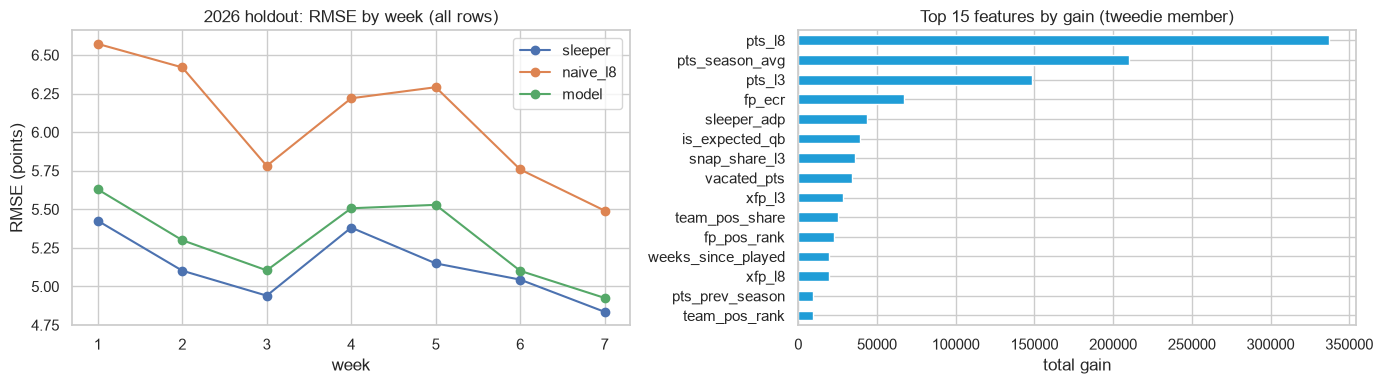

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
wk = pd.DataFrame({k: ((v - ev_test.act) ** 2).groupby(ev_test.week).mean() ** .5 for k, v in preds.items()})
wk.plot(marker="o", ax=axes[0])
axes[0].set(title="2026 holdout: RMSE by week (all rows)", xlabel="week", ylabel="RMSE (points)")
first = MEMBERS[champion][0]
imp = pd.Series(final_model[first][1].booster_.feature_importance("gain"), X.columns).sort_values(ascending=False).head(15)
imp.sort_values().plot.barh(ax=axes[1], color="#209dd7")
axes[1].set(title=f"Top 15 features by gain ({first} member{', points part' if first == 'hurdle' else ''})", xlabel="total gain", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "03_holdout_by_week_and_importance.png", dpi=110); plt.show()

**Findings**


- **2026 weeks 1-7 (3,069 rows, used once), champion = average of Tweedie and hurdle:**
  - **RMSE 5.313 against Sleeper's 5.137 (+3.4%)**, down from +4.2% in the previous version. MAE 3.556 against 3.318.
  - Played only: RMSE 5.608 against 5.484 (+2.3%), MAE 3.870 against 3.779 (+2.4%).
  - **Start/sit hit rate 0.562 against Sleeper's 0.554: better on close calls.** Within-week Spearman 0.427 against 0.438 (previously 0.400).
- Paired weekly tests (7 weeks): still worse on squared error (p = 0.006 all rows, 0.021 played) and absolute error (p = 0.001, 0.040).
- Stable across seeds: 5.314 +/- 0.003.
- **By position (RMSE, all rows):** TE 4.51 vs 4.47 and WR 5.64 vs 5.53 are close. RB 5.46 vs 5.19. **QB 5.47 vs 5.06**, down from 5.57.
- 13% better than the naive baseline on RMSE and 16% on MAE.

## Summary


1. **The independent model (no weekly projections) improved but still trails Sleeper on accuracy.** Holdout RMSE is 5.313 against 5.137 (+3.4%, down from +4.2%), and +2.3% on players who played. **It is now better than Sleeper on close start/sit calls** (0.562 against 0.554 on the holdout; 0.547 against 0.560 in CV, so treat that as a tie rather than a win).
2. **What moved it:**
   - Correcting the next-man-up logic: IR, cuts and trades now count as vacated usage, and the expected QB is last game's starter (it matches the real starter 89.8% of the time, against a 21% false "QB change" rate before).
   - League-relative team values, which removed season drift.
   - Averaging two models that err in opposite directions.
3. **The requested matchup features help, but modestly.** Defense strength (EPA allowed, schedule-adjusted points allowed by position) and the QB's passing ability each add +0.02 to +0.05 partial correlation at every position. In the model they are worth about 0.005 RMSE each, because a player's own history already contains most of his QB and opponents. Role (who starts, who's out) matters far more.
4. **The remaining gap is late information:** Questionable game-day decisions, inactives, benchings. Sleeper's final snapshot has them; pre-game facts don't. Closing it needs game-day inactive lists or published depth charts (with a point-in-time audit; nflverse changes the depth-chart source in 2025).